# Streamlines, pathlines and streaklines

- **Streamline** — freeze time, follow the arrows.
- **Pathline** — follow one particle while time runs.
- **Streakline** — where all the particles released from one point are *now* (a smoke or dye line).

Steady flow: all three are the same curve. Unsteady flow: they are not.

In [20]:
import numpy as np
import matplotlib.pyplot as plt

def steady(x, y, t):
    """Flow past a cylinder of radius 1.  No t anywhere -> steady."""
    r2 = x**2 + y**2
    return 1 - (x**2 - y**2)/r2**2, -2*x*y/r2**2

def unsteady(x, y, t):
    """Uniform stream that wags up and down with period 4."""
    return 1 + 0*x, 0.7*np.sin(2*np.pi*t/4) + 0*x

def wavy(x, y, t):
    """Cross-flow that varies along x as well, and reverses every half period."""
    return 1 + 0*x, 0.7*np.sin(2*np.pi*x/4)*np.cos(2*np.pi*t/4)

def arrows(ax, vel, t, xlim, ylim, nx=18, ny=10, mask=None, **kw):
    """Background arrows = the velocity field at this instant."""
    X, Y = np.meshgrid(np.linspace(*xlim, nx), np.linspace(*ylim, ny))
    U, V = vel(X, Y, t)
    if mask is not None:                       # e.g. hide arrows inside a body
        keep = ~mask(X, Y)
        X, Y, U, V = X[keep], Y[keep], U[keep], V[keep]
    # angles/scale in data units so the arrows really are tangent to the streamlines
    opts = dict(color='0.6', width=0.003, angles='xy', scale_units='xy', scale=4)
    return ax.quiver(X, Y, U, V, **{**opts, **kw})

The three integrators. Same Euler step every time — the only difference is what happens to `t`.

In [21]:
dt = 0.01

def streamline(vel, x, y, t, n=500):
    """t is FROZEN: follow the arrows in one snapshot."""
    pts = []
    for _ in range(n):
        u, v = vel(x, y, t)
        x, y = x + u*dt, y + v*dt
        pts.append((x, y))
    return np.array(pts)

def pathline(vel, x, y, t, n=500):
    """t ADVANCES: follow one particle."""
    pts = []
    for _ in range(n):
        u, v = vel(x, y, t)
        x, y = x + u*dt, y + v*dt
        t = t + dt
        pts.append((x, y))
    return np.array(pts)

def streakline(vel, x0, y0, t_now, n=500):
    """n particles released at (x0,y0), one per step.  Where are they now?"""
    X, Y = np.full(n, float(x0)), np.full(n, float(y0))
    t = t_now - n*dt
    for k in range(n):
        u, v = vel(X[:k+1], Y[:k+1], t)     # only the ones already released
        X[:k+1] += u*dt
        Y[:k+1] += v*dt
        t += dt
    return X, Y

## Step through it

The same Euler steps, but big ones so you can see them.  Use the step buttons under each
animation: on the left one particle moves one step at a time, on the right a **new** particle
is released every step and they all move together.

In [22]:
from matplotlib.animation import FuncAnimation
plt.rcParams['animation.html'] = 'jshtml'

def step_demo(vel, x0, y0, xlim, ylim, nstep=24, DT=0.25, mask=None, circle=None):
    """Left: one particle, one Euler step per frame.  Right: a new particle every step."""

    path = [(float(x0), float(y0))]                    # ONE particle
    for k in range(nstep):
        x, y = path[-1]
        u, v = vel(x, y, k*DT)
        path.append((x + u*DT, y + v*DT))
    path = np.array(path)

    X, Y = np.full(nstep+1, float(x0)), np.full(nstep+1, float(y0))
    streak = [(X[:1].copy(), Y[:1].copy())]            # a NEW particle every step
    for k in range(nstep):
        u, v = vel(X[:k+1], Y[:k+1], k*DT)             # move everyone released so far
        X[:k+1] += u*DT
        Y[:k+1] += v*DT
        streak.append((X[:k+2].copy(), Y[:k+2].copy()))  # then release the next one

    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
    a1.set_title('pathline: ONE particle'); a2.set_title('streakline: a NEW particle each step')
    gx, gy = (xlim[0]+0.2, xlim[1]-0.2), (ylim[0]+0.2, ylim[1]-0.2)
    qs = []
    for a in (a1, a2):
        a.set(xlim=xlim, ylim=ylim)
        if circle:
            a.add_patch(plt.Circle((0, 0), circle, color='0.3'))
            a.set_aspect('equal')
        qs.append(arrows(a, vel, 0, gx, gy, nx=15, ny=7, mask=mask, width=0.006, scale=3))
    l1, = a1.plot([], [], 'o-', color='C0', ms=4)
    l2, = a2.plot([], [], 'o-', color='C1', ms=4)
    dot, = a1.plot([], [], 'o', color='C0', ms=11)
    fig.tight_layout(rect=(0, 0, 1, 0.90))

    def step(k):
        t = k*DT
        for q in qs:
            q.set_UVC(*vel(q.X, q.Y, t))
        l1.set_data(path[:k+1, 0], path[:k+1, 1])
        dot.set_data(path[k:k+1, 0], path[k:k+1, 1])
        l2.set_data(*streak[k])
        fig.suptitle(f'step {k}   t = {t:.2f}', y=0.99)

    anim = FuncAnimation(fig, step, frames=nstep+1, interval=400)
    plt.close(fig)
    return anim

step_demo(unsteady, 0, 0, (-0.5, 6.5), (-1.5, 1.5))

Now the field that varies in space as well as time — every particle gets pushed by a different
arrow.  Watch for the fluke here: this particular particle keeps pace with the pattern and so barely
leaves the axis, while the dye line released from the same point swings out to $y = -2$.

In [23]:
step_demo(wavy, 0, 0, (-0.5, 6.5), (-2.5, 2.5))

And steady flow: each new particle simply retraces the steps of the one before it, so the two panels build up the same curve.

## Steady flow — one curve, three names

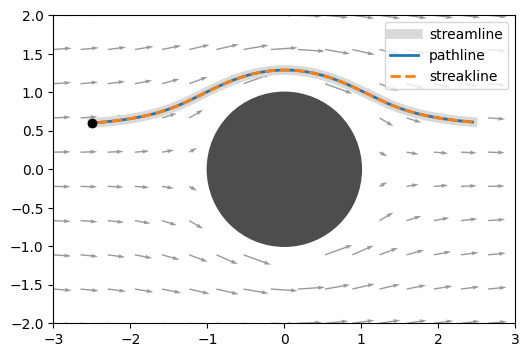

In [25]:
x0, y0 = -2.5, 0.6

s      = streamline(steady, x0, y0, t=0)
p      = pathline(steady, x0, y0, t=0)
kx, ky = streakline(steady, x0, y0, t_now=5)

plt.figure(figsize=(9, 4))
arrows(plt.gca(), steady, 0, (-3, 3), (-2, 2), mask=lambda x, y: x**2 + y**2 < 1.3)
plt.gca().add_patch(plt.Circle((0, 0), 1, color='0.3'))
plt.plot(s[:, 0], s[:, 1], lw=7, color='0.85', label='streamline')
plt.plot(p[:, 0], p[:, 1], lw=2, label='pathline')
plt.plot(kx, ky, '--', lw=2, label='streakline')
plt.plot(x0, y0, 'ko')
plt.gca().set_aspect('equal'); plt.xlim(-3, 3); plt.ylim(-2, 2)
plt.legend(); plt.show()

## Unsteady flow — three different curves

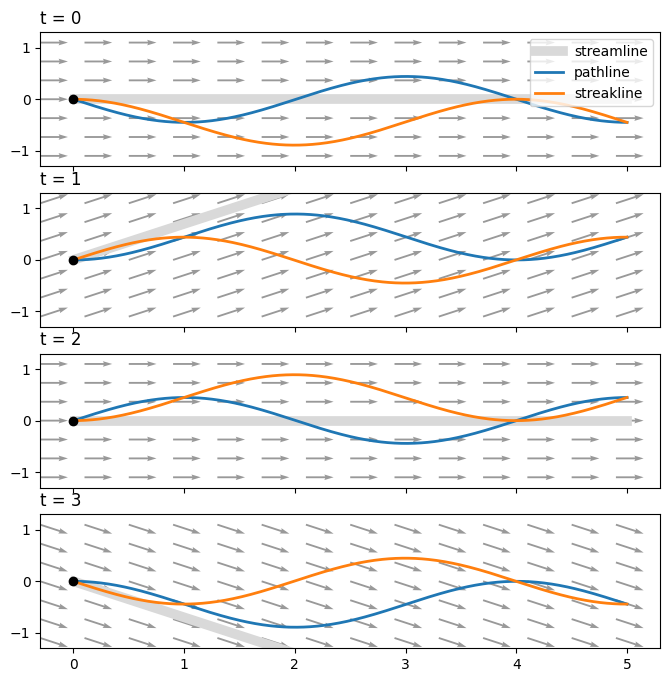

In [26]:
fig, axes = plt.subplots(4, 1, figsize=(8, 8), sharex=True)

for ax, t in zip(axes, [0, 1, 2, 3]):
    s      = streamline(unsteady, 0, 0, t)
    p      = pathline(unsteady, 0, 0, t - 5)   # particle released 5 units ago
    kx, ky = streakline(unsteady, 0, 0, t_now=t)

    arrows(ax, unsteady, t, (-0.3, 5.3), (-1.1, 1.1), nx=15, ny=7)
    ax.plot(s[:, 0], s[:, 1], lw=7, color='0.85', label='streamline')
    ax.plot(p[:, 0], p[:, 1], lw=2, label='pathline')
    ax.plot(kx, ky, lw=2, label='streakline')
    ax.plot(0, 0, 'ko')
    ax.set_xlim(-0.3, 5.3); ax.set_ylim(-1.3, 1.3)
    ax.set_title(f't = {t}', loc='left')

axes[0].legend(loc='upper right')
plt.show()

## Unsteady *and* varying in space — now the streamline curves too

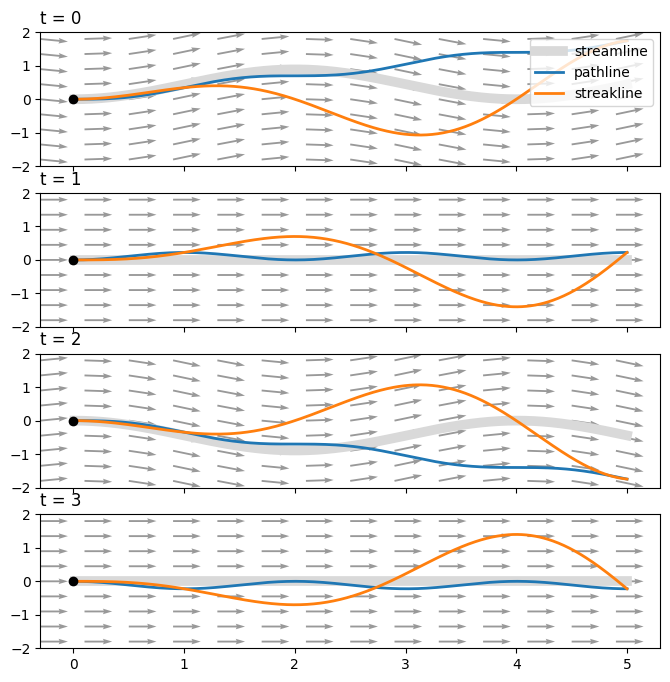

In [27]:
fig, axes = plt.subplots(4, 1, figsize=(8, 8), sharex=True)

for ax, t in zip(axes, [0, 1, 2, 3]):
    s      = streamline(wavy, 0, 0, t)
    p      = pathline(wavy, 0, 0, t - 5)
    kx, ky = streakline(wavy, 0, 0, t_now=t)

    arrows(ax, wavy, t, (-0.3, 5.3), (-1.8, 1.8), nx=15, ny=9)
    ax.plot(s[:, 0], s[:, 1], lw=7, color='0.85', label='streamline')
    ax.plot(p[:, 0], p[:, 1], lw=2, label='pathline')
    ax.plot(kx, ky, lw=2, label='streakline')
    ax.plot(0, 0, 'ko')
    ax.set_xlim(-0.3, 5.3); ax.set_ylim(-2, 2)
    ax.set_title(f't = {t}', loc='left')

axes[0].legend(loc='upper right')
plt.show()

## Animation

In [28]:
from matplotlib.animation import FuncAnimation
plt.rcParams['animation.html'] = 'jshtml'

vel = wavy                       # <- swap to `unsteady` for the uniform case

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.set(xlim=(-0.5, 5.5), ylim=(-2, 2))
q = arrows(ax, vel, 0, (-0.3, 5.3), (-1.8, 1.8), nx=15, ny=9)
ls, = ax.plot([], [], lw=7, color='0.85', label='streamline')
lp, = ax.plot([], [], lw=2, label='pathline')
lk, = ax.plot([], [], lw=2, label='streakline')
ax.plot(0, 0, 'ko'); ax.legend(loc='upper right')

def frame(i):
    t = i*0.1
    s      = streamline(vel, 0, 0, t)
    p      = pathline(vel, 0, 0, t - 5)
    kx, ky = streakline(vel, 0, 0, t_now=t)
    q.set_UVC(*vel(q.X, q.Y, t))
    ls.set_data(s[:, 0], s[:, 1])
    lp.set_data(p[:, 0], p[:, 1])
    lk.set_data(kx, ky)
    ax.set_title(f't = {t:.1f}')

anim = FuncAnimation(fig, frame, frames=80, interval=60)
plt.close(fig)
anim